In [405]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from package import Ham

In [406]:
def bisection(f, a, b, tol=1e-6, max_iter=100):
    if f(a) == 0: return a
    if f(b) == 0: return b
 
    for _ in range(max_iter):
        # Trova il punto medio
        c = (a + b) / 2.0
        fc = f(c)

        if (b - a) / 2.0 < tol or fc == 0:
            return c

        if f(a) * fc < 0:
            b = c  # left
        else:
            a = c  # right

    return (a + b) / 2.0

Unit of the system:
1. \[B\] = $T$ (tesla)
2. \[Q\] = $|qp|$ (particle charge)
3. \[M\] = $mp$ (particle mass)
4. \[E\]= $eV$ (electron Volt)

Temporal and spatial unit:

1. $l$ = \[L\] = $\frac{\sqrt{eV\, m_p}}{|q_p| \, T}$ = $ \sqrt{\frac{m_p[kg]}{|q_p[e]|\;|q_p|[C]}}  \; m$
2. $\tau$ = \[T\] = $\frac{m_p}{|q_p| T}$ = ${\frac{m_p [ kg ]  }{|q_p| [C]}} \; s$ 

Velocity unit:

3. $\upsilon$ = \[V\] = $\sqrt{\frac{eV}{\, m_p}}$ = $\sqrt{\frac{|q_p| [C]}{m_p [ kg ]\; |q_e|[e] }} \; s$ 


where the units $m$, $s$, $kg$, $C$, $e$, are respectivly meters, seconds, kilos, Coulombs, and elementray unit charges.

# Potential

https://linkinghub.elsevier.com/retrieve/pii/S0375960118309587


In [410]:
qp_e = 1
mp_me = 1

# sign of the charge
sq =  -1 


# Electron constants in SI units (kg, Coulombs)
mp = mp_me *  9.1093837015e-31  # Electron mass in kg
qp_C = qp_e * 1.602176634e-19  # Elementary charge constant (positive magnitude)

l = np.sqrt(mp/qp_e/qp_C)
tau = mp/qp_C
upsilon = np.sqrt(qp_C/mp/qp_e)

# magnetid field intensity
Bz = 4

In [411]:
def V_eff(r, pth, pz, Bz, sq):
# parameters: par = [p_theta, p_z, omega, m, H, z_0, theta_0]    
    V = 0.5*( pth/r - sq*0.5*Bz*r )**2 + 0.5*(pz)**2   # 
    return V

# prompt losses in the space $E_\perp, p_\theta$

1. the value $p_z$ is kept constant and is decoupled from the evolution of $E_\perp$ and$p_\theta$.
2. the trajectory is a loss orbit if the largest turning point is $\text{Max}(r_\text{turn})>r_\text{border}$

the generalized cylindrical coordinates
- $r, \theta, z, \dot{r}, \dot{\theta}, \dot{z}$ : 
    
    $x=r\cos(\theta)$, $y=r\sin(\theta)$, $z=z$

    $\dot{r} = d_t r$, $\dot{\theta} = d_t\theta$, $\dot{z}=d_t z$

Dynamical variables
- $v_r, v_\theta, v_z$ :

    $v_r = \dot{r}$, $v_\theta = r\dot{\theta}$, $v_z = \dot{z}$

Generalized momentums
- $p_r, p_z, p_\theta$ : 
    
    $p_r = (mv_r + qA_r)$, $p_\theta = (m v_\theta r + q rA_\theta)$, $p_z = (mv_z + qA_z)$ 


### Energy distribution

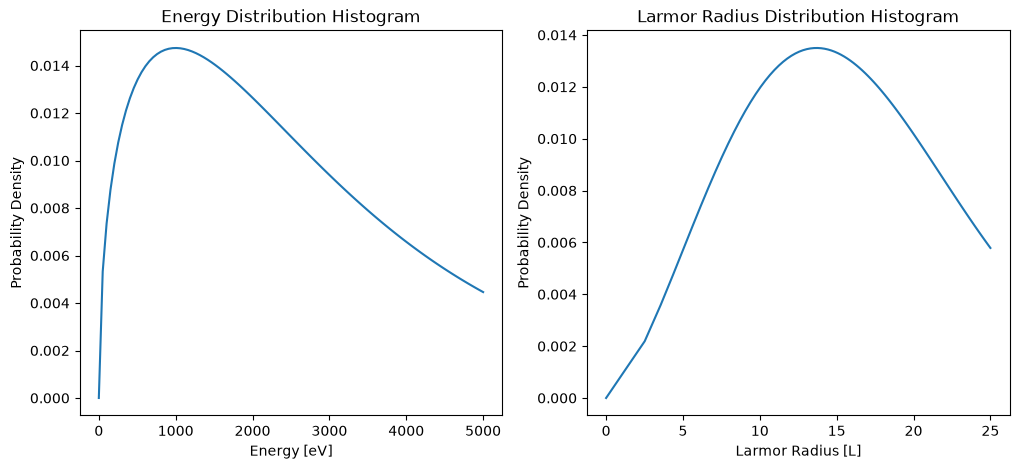

In [412]:
T = 1000
E = np.linspace(0, 5*T, 100)
fE = np.sqrt(E)*np.exp(-E/(2*T))

rho =  np.sqrt(2*E)/Bz
frho = fE*np.sqrt(rho)

fig, ax =plt.subplots(1,2, figsize=(12,5))

#ax[1].hist(rho, bins=20, histtype='barstacked', alpha=0.5, label='Larmor Radius Distribution [L]', density=True)
ax[1].plot(rho, frho/np.sum(frho))
ax[1].set_xlabel('Larmor Radius [L]')
ax[1].set_ylabel('Probability Density')
ax[1].set_title('Larmor Radius Distribution Histogram')

#ax[0].hist(E, bins=20, histtype='barstacked', alpha=0.5, label='Energy Distribution [eV]', density=True)
ax[0].plot(E, fE/np.sum(fE))
ax[0].set_xlabel('Energy [eV]')
ax[0].set_ylabel('Probability Density')
ax[0].set_title('Energy Distribution Histogram')
plt.show()

### Velocity grid

Text(0.5, 1.0, 'Velocity grid')

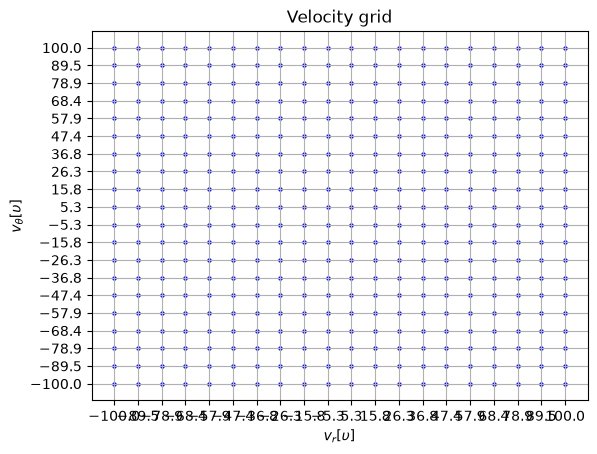

In [413]:
vmax = np.sqrt(2*E[-1])

vr = np.linspace(-1,1, 20)*vmax
vth = np.linspace(-1,1, 20)*vmax
VR, VTH = np.meshgrid(vr,vth)
plt.scatter(VR,VTH,color='blue', alpha=0.9, s=5)
plt.grid()
plt.xticks(vr)
plt.yticks(vth)
plt.xlabel('$v_r [\\upsilon]$')
plt.ylabel('$v_\\theta [\\upsilon]$')
plt.title('Velocity grid')

### Distribution in Velocity space

Text(0.5, 1.0, 'thermal distribution function')

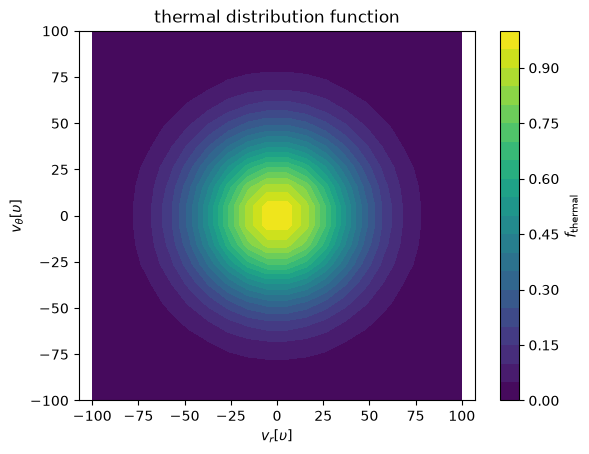

In [414]:
fth = np.exp(-(VTH**2 + VR**2)/(2*T))

plt.contourf( VR, VTH, fth, levels=20)
plt.colorbar(label='$f_\\text{thermal}$')
plt.xlabel('$v_r [\\upsilon]$')
plt.ylabel('$v_\\theta [\\upsilon]$')
plt.axis('equal')
plt.title('thermal distribution function')

### Set the position

In [419]:
# limiter of the machine
rmax =  0.1/l # 10cm of minor radius

r = rmax - 1

### Compute the COM for each grid point

In [420]:
E = 0.5*(VR**2 + VTH**2)
PTH = VTH*r + sq*0.5*Bz*r**2

### Find the outer inversion point $r_2$ for each orbit 

In [421]:
F = []
for i in range(len(E.flatten())):
    Ei = E.flatten()[i]
    PTHi = PTH.flatten()[i]
    f = lambda r: Ei - V_eff(r, PTHi,0, Bz, sq)
    h = 0.01
    rL = r
    rR = r + h

    while f(rL) * f(rR) > 0:
        rL = rR
        rR = rL + h
        if rL > rmax:
            Fi = 0
            break
    if rR < rmax:
        Fi = 1
    else:
        r2  =  bisection(f, rL, rR)
        if r2> rmax:
            Fi = 0
        else:
            Fi = 1
    F.append(Fi)

### Plot the prompt losses

Text(0.5, 1.0, 'Velocity grid at r=41937.29 [L]')

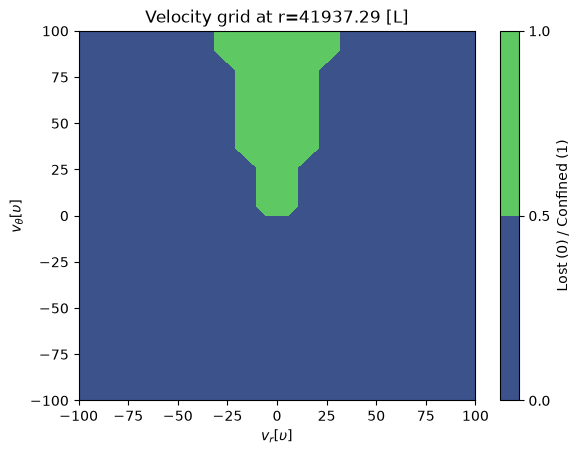

In [422]:
plt.contourf( VR, VTH, np.reshape(F, VR.shape), levels=[0,0.5,1])
plt.colorbar(label='Lost (0) / Confined (1)')
plt.xlabel('$v_r [\\upsilon]$')
plt.ylabel('$v_\\theta [\\upsilon]$')
plt.title('Velocity grid at r={:.2f} [L]'.format(r))

### 

In [430]:
def prompt_losses(vr, vth, r, Bz, sq, rmax):

    VR, VTH = np.meshgrid(vr,vth)
    E = 0.5*(VR**2 + VTH**2)
    PTH = VTH*r + sq*0.5*Bz*r**2
    F = []
    for i in range(len(E.flatten())):
        Ei = E.flatten()[i]
        PTHi = PTH.flatten()[i]
        Fi = islost(Ei, PTHi, r, Bz, sq, rmax)
        F.append(Fi)
    return np.reshape(F,VR.shape)

def islost(E, pth, r, Bz, sq, rmax):
    f = lambda r: E - V_eff(r, pth, 0, Bz, sq)
    h = 0.01
    rL = r
    rR = r + h

    while f(rL) * f(rR) > 0:
        rL = rR
        rR = rL + h
        if rL > rmax:
            Fi = 0
            break
    if rR < rmax:
        Fi = 1
    else:
        r2  =  bisection(f, rL, rR)
        if r2> rmax:
            Fi = 0
        else:
            Fi = 1
    return Fi


### Prompt losses at different positions

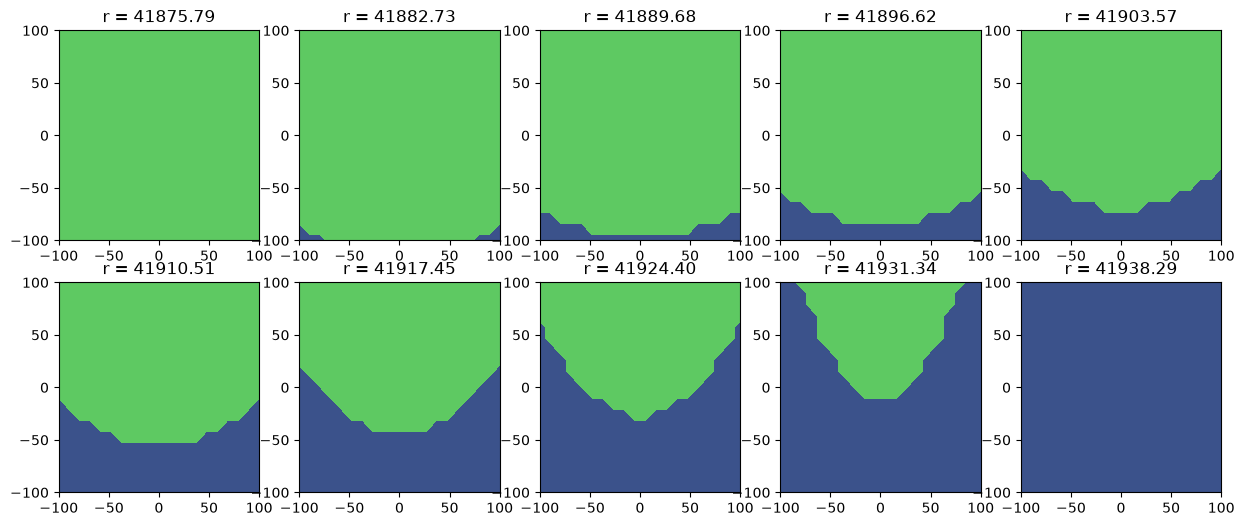

In [431]:
fig, ax = plt.subplots(2,5, figsize=(15,6))
ax = ax.flatten()
for i, r in enumerate(np.linspace((rmax-2.5*rho.max()), rmax, len(ax))):
    F = prompt_losses(vr, vth, r, Bz, sq, rmax)
    ax[i].contourf( VR, VTH, np.reshape(F, VR.shape), levels=[0,0.5,1])
    ax[i].set_title(f'r = {r:.2f}')

### Mean velocity profile moving towards the edge

In [187]:
meanVr = []
meanVth = []

Nr =100

for i, r in enumerate(np.linspace((rmax-2.5*rho.max()), rmax, Nr)):
    F = prompt_losses(vr, vth, r, Bz, sq, rmax)
    meanVr.append(np.sum(F*VR)/np.sum(F))
    meanVth.append(np.sum(F*VTH)/np.sum(F))

meanVr = np.array(meanVr)
meanVth = np.array(meanVth)

C:\Users\Utente\AppData\Local\Temp\ipykernel_15612\1359791475.py:8: RuntimeWarning: invalid value encountered in scalar divide
  meanVr.append(np.sum(F*VR)/np.sum(F))
C:\Users\Utente\AppData\Local\Temp\ipykernel_15612\1359791475.py:9: RuntimeWarning: invalid value encountered in scalar divide
  meanVth.append(np.sum(F*VTH)/np.sum(F))


Text(0.5, 1.0, 'Poloidal flow')

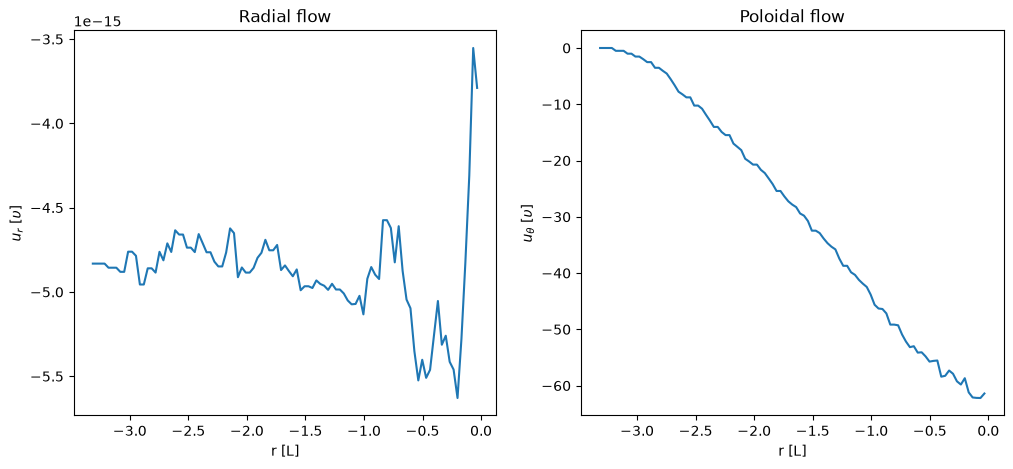

In [188]:
fig, ax = plt.subplots(1,2, figsize=(12,5))

ax[0].plot( np.linspace(0.9999, 1, Nr)*rmax - rmax, meanVr)
ax[1].plot( np.linspace(0.9999, 1, Nr)*rmax - rmax, meanVth)

ax[0].set_xlabel('r [L]')
ax[1].set_xlabel('r [L]')

ax[0].set_ylabel('$u_r $ $[\\upsilon]$')
ax[1].set_ylabel('$u_\\theta$ $[\\upsilon]$')

ax[0].set_title('Radial flow')
ax[1].set_title('Poloidal flow')

# Macroscopic flow due to first orbit losses

## Class OrbitLoss

In [519]:
class OrbitLoss:
    def __init__(self, mp_me, qp_e, sq):
        self.mp = mp_me *  9.1093837015e-31
        self.qp_C = qp_e * 1.602176634e-19 
        self.qp_e = qp_e
        self.sq = sq

        # set the dimensions
        self.l = np.sqrt(self.mp/self.qp_C/self.qp_e)
        self.tau = self.mp/self.qp_C
        self.upsilon = np.sqrt(self.qp_C/self.mp/self.qp_e)


    def set_potential(self, V):
        # the potential is set to have radial symmetry: no dependences on theta or z
        # It depends on equilibrium parameters: Vector potential Ath, Az
        # It depends on COM, like Energy and momentums: E, pth, pz
        self.V = V

    def set_vector_potential(self, Ath, Az):
        self.Ath = Ath
        self.Az = Az

    def set_machine(self, rmax):
        self.rmax = rmax
        
    def set_velocity_grid(self, vr, vth):
        self.vr = vr
        self.vth = vth
        self.vel_extend = (vr[0], vr[-1], vth[0], vth[-1])

    def mesh_velocity(self):
        # return VR, VTH
        return np.meshgrid(self.vr, self.vth)

    def get_COM(self, r, vz):
        # return E, PTH, PZ
        VR, VTH = self.mesh_velocity()
        E = 0.5*(VR**2 + VTH**2 + vz**2)
        PTH = VTH*r + self.sq*self.Ath(r)
        return E, PTH
    
    def islost(self, E, pth, pz, r):
        f = lambda r: E - self.V(r, pth, pz, self.Ath, self.Az, self.sq)
        h = 0.01
        rL = r
        rR = r + h
        while f(rL) * f(rR) > 0:
            rL = rR
            rR = rL + h
            if rL > self.rmax:
                F = 0
                break
        if rR < self.rmax:
            F = 1
        else:
            r2  =  bisection(f, rL, rR)
            if r2 > self.rmax:
                F = 0
            else:
                F = 1
        return F

    def compute_losses(self, r, vz):
        E, PTH = self.get_COM(r, vz)
        pz = vz + self.sq*self.Az(r)
        F = []
        for i in range(len(E.flatten())):
            Ei = E.flatten()[i]
            PTHi = PTH.flatten()[i]
            Fi = self.islost(Ei, PTHi, pz, r)
            F.append(Fi)
        return np.reshape(F, E.shape)

In [520]:
# machine
rmax = 0.1

# Equilibrium
Bz = 4

In [521]:
def V(r, pth, pz, Ath, Az, sq):
    V = 0.5*( pth - sq*Ath(r) )**2/r**2 + 0.5*(pz - sq*Az(r))**2   # 
    return V

def Ath(r):
    return 0.5*Bz*r**2

def Az(r):
    return 0


In [554]:
ion = OrbitLoss(1000, 1, 1)

ion.set_potential(V)
ion.set_vector_potential(Ath, Az)

ion.set_machine(rmax/ion.l)


Emax = 1000 # eV
vmax = np.sqrt(2*Emax)

vr = np.linspace(-1,1, 100)*vmax
vth = np.linspace(-1,1, 100)*vmax

ion.set_velocity_grid(vr, vth)

In [555]:
electr = OrbitLoss(1, 1, -1)

print(electr.l)

electr.set_potential(V)
electr.set_vector_potential(Ath, Az)


electr.set_machine(rmax/electr.l)


Emax = 1000 # eV
vmax = np.sqrt(2*Emax)

vr = np.linspace(-1,1, 100)*vmax
vth = np.linspace(-1,1, 100)*vmax

electr.set_velocity_grid(vr, vth)

2.3844559344986274e-06


### Larmor radius scales vs minor radius

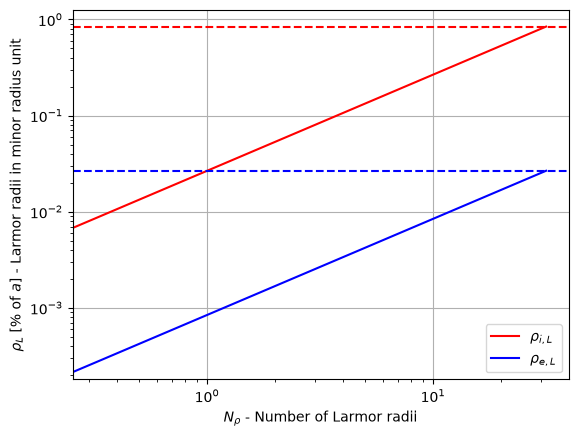

In [556]:
N = np.linspace(0, np.sqrt(Emax), 100) # N° larmor radius

plt.plot(N, N*(np.sqrt(2)*ion.l/Bz)*100/rmax, label='$\\rho_{i,L}$' , color='red')
plt.plot(N, N*(np.sqrt(2)*electr.l/Bz)*100/rmax, label='$\\rho_{e,L}$' , color='blue')

plt.axhline(np.sqrt(Emax)*(np.sqrt(2)*ion.l/Bz)*100/rmax, color='red', linestyle='dashed')
plt.axhline(np.sqrt(Emax)*(np.sqrt(2)*electr.l/Bz)*100/rmax, color='blue', linestyle='dashed')


plt.xscale('log')
plt.yscale('log')
plt.legend()

plt.xlabel('$N_\\rho$ - Number of Larmor radii')
plt.ylabel('$ \\rho_L$ $[\\text{% of } a]$ - Larmor radii in minor radius unit')
plt.grid()
plt.show()

### test for only one species

In [557]:
r = rmax*0.9999  # range of position of interest
vz = 0

Fe = electr.compute_losses(r/electr.l, vz)

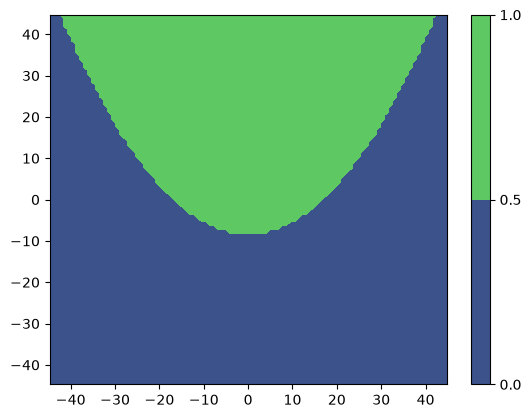

In [558]:
plt.contourf( Fe, levels=[0,0.5,1], extent = electr.vel_extend )
plt.colorbar()

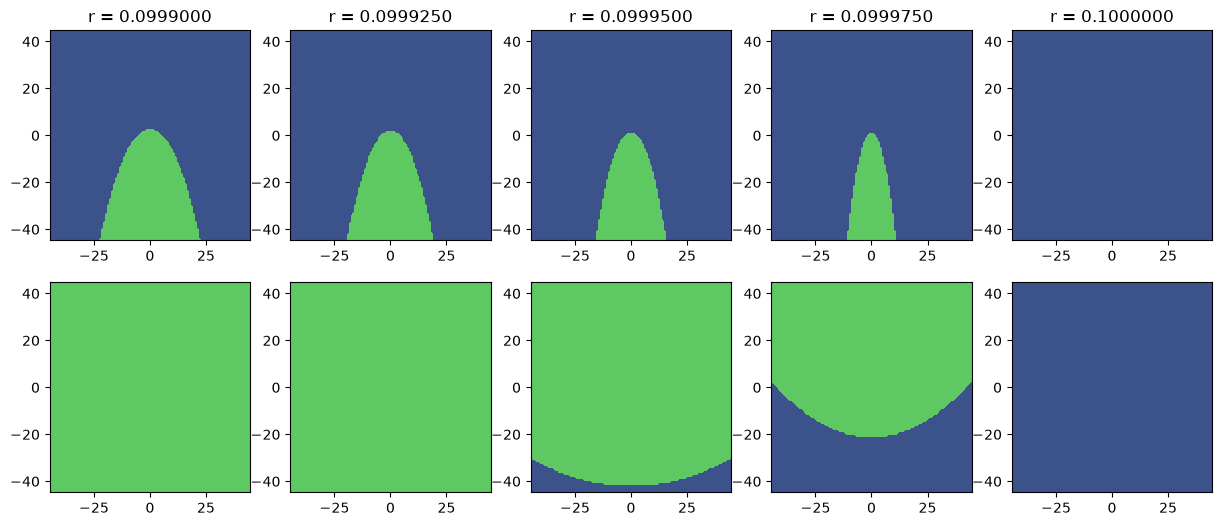

In [559]:
Nr = 5
R = np.linspace(rmax*.999, rmax, Nr)  # range of position of interest
vz = 0

fig, ax = plt.subplots(2, Nr, figsize=(15,6))

for i in range(Nr):
    r = R[i]
    Fi = ion.compute_losses(r/ion.l, vz)
    Fe = electr.compute_losses(r/electr.l, vz)

    ax[0,i].contourf( Fi, levels=[0,0.5,1], extent = ion.vel_extend )
    dr = rmax-r
    ax[0,i].set_title(f'r = {r:.7f}'.format(dr))
    ax[1,i].contourf( Fe, levels=[0,0.5,1], extent = electr.vel_extend )


### Compute the flow and temperature

In [561]:
def density(f, F):
    return np.sum(f * F)

def flow(f, F, v):
    r = np.sum(v*f*F)
    d = density(f,F)
    return r/d

def temp(f, F, v):
    u = flow(f, F, v)
    r = np.sum((u-v)**2*f*F)
    d = density(f,F)
    return r/d

C:\Users\Utente\AppData\Local\Temp\ipykernel_15612\1148992617.py:7: RuntimeWarning: invalid value encountered in scalar divide
  return r/d


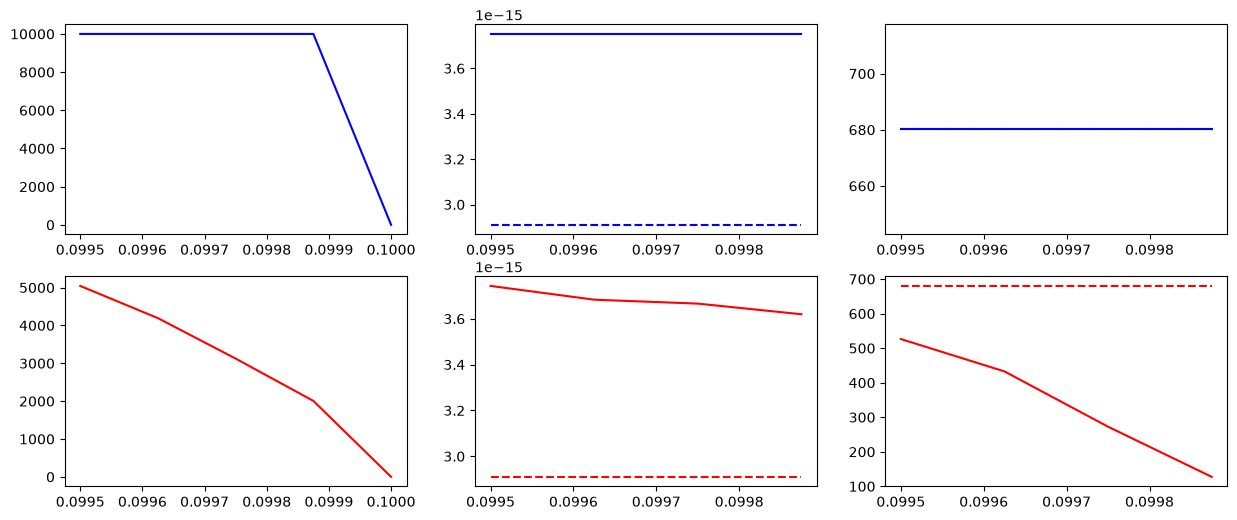

In [565]:
Nr = 5
R = np.linspace(rmax*.995, rmax, Nr)  # range of position of interest
vz = 0
fe = 1
fi = 1

VR, VTH = np.meshgrid(vr,vth)
fig, ax = plt.subplots(2, 3, figsize=(15,6))

ne = []
ni = []
vre = []
vri = []
vthe = []
vthi = []
Tre = []
Tri = []
Tthe = []
Tthi = []

for i in range(Nr):
    r = R[i]
    Fi = ion.compute_losses(r/ion.l, vz)
    Fe = electr.compute_losses(r/electr.l, vz)
    ne.append(density(fe, Fe))
    ni.append(density(fi, Fi))
    vre.append(flow(fe, Fe, VR))
    vri.append(flow(fi, Fi, VR))
    vthe.append(flow(fe, Fe, VTH))
    vthi.append(flow(fe, Fe, VTH))
    Tre.append(temp(fe, Fe, VR))
    Tri.append(temp(fi, Fi, VR))
    Tthe.append(temp(fe, Fe, VTH))
    Tthi.append(temp(fe, Fe, VTH))

ax[0,0].plot(R, ne, color='blue')
ax[1,0].plot(R, ni, color='red')

ax[0,1].plot(R, vre, color='blue')
ax[0,1].plot(R, vthe, color='blue', linestyle='dashed')
ax[1,1].plot(R, vri, color='red')
ax[1,1].plot(R, vthi, color='red', linestyle='dashed')

ax[0,2].plot(R, Tre, color='blue')
ax[0,2].plot(R, Tthe, color='blue', linestyle='dashed')
ax[1,2].plot(R, Tri, color='red')
ax[1,2].plot(R, Tthi, color='red', linestyle='dashed')

### Machine border and dimensions

In [ ]:
# limiter of the machine
xmax = np.max(rho) * 1.5

dx = 0.0001     # resolution
x = np.arange(0.0001, 1, dx) * xmax

In [ ]:
# in the uniform case, the dinamics along z is decoupled from the perpendicolar plane
pz = 0

# vperp [m_e m/tau]= sqrt(2E/m) = sqrt(2E[eV]/m[m_e] /m_e/q_e)
E = np.linspace( 10 , 1000, 20 ) # [eV]  # E = Eperp

pthmax = np.max(np.sqrt(2*E[-1])*x + sq*x**2*Bz/2) # (m_e eV)**1/2 *m
pthmin = np.min(- np.sqrt(2*E[0])*xmax + sq*xmax**2*Bz/2) # (m_e eV)**1/2 *m

p_theta = np.linspace( 2*pthmin, 2*pthmax, 21 )

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for pthi in p_theta[::int(len(p_theta)/10)]:
    y = V_eff(x, pthi, pz, Bz, sq)
    ax[0].plot(x,y, label= rf'$p_{{\theta}}={pthi:.1f}$' )

ax[0].legend()
ax[0].set_ylim(0,1000)
ax[0].axvline(xmax, linestyle='dashed', color='red', linewidth = 3)
ax[0].set_title(rf'Effective Potential vs $p_\theta$')
ax[0].set_xlabel(' $r$ [L] - Radial distance')
ax[0].set_yticks(E[::int(len(E)/10)])
ax[0].grid()
ax[0].set_ylabel('$E_\\perp$ [eV] - Perpendicular energy')

ax[1].fill_between(E,  -np.sqrt(E[-1]-E), np.sqrt(E[-1]-E), color='red', alpha = 0.4 , label='$E_{\\text{tot}}<1\\text{keV}$')
ax[1].legend()
ax[1].grid()
ax[1].set_xlabel('$E_\\perp$ [eV] - Perpendicular energy')
ax[1].set_ylabel('$p_z \\; [\\text{eV }m_e]^{1/2}$ - axial momentum')


# Build the trajectory for each value of p_z

In [ ]:
df = pd.DataFrame()

for pthi in p_theta:
    V = lambda r : V_eff(r, pth=pthi, pz=pz, Bz=Bz, sq=sq) 
    system = Ham(V, E, x)
    system.turns()
    system.equilibrium()
    if len(system.equi_point['V']) != 0:
        if system.equi_point['V'].min() < E[-1] and system.equi_point['x'].min() < xmax:
            system.get_regions()
            system.get_trajectories()
            system.trajec.pth = np.array( [pthi]*len(system.trajec.index) )
            df = pd.concat([df,system.trajec.df()], ignore_index = True)

In [ ]:
# find the losses
df[ 'prompt' ] = df['x2'] > xmax

In [ ]:
fig, ax = plt.subplots()
df[df['prompt'] == True].plot(x = 'E', y = 'pth', kind='scatter', ax=ax, color='red')
df[df['prompt'] == False].plot(x = 'E', y = 'pth', kind='scatter', ax=ax, color = 'blue')

# Trasformazione nella distribuzione di velociità

plot delle perdite da prompt in $v_x, v_y$ a diverse posizioni $r$ 

In [ ]:
def v(pth, E, theta, r, Bz):
    vth = pth/r - sq*r*Bz*0.5
    vr = np.sqrt( 2*E - vth**2)
    vx = np.cos(theta)*vr + np.sin(theta)*vth
    vy = -np.sin(theta)*vr + np.cos(theta)*vth
    return vx, vy

In [ ]:
fig, ax = plt.subplots(4,2, figsize=(9, 18))

ax = ax.flatten()
r = np.linspace( xmax/8, xmax, 8)

for i, ri in enumerate(r):
    Ei = df['E'][df['prompt']==True]
    pthi = df['pth'][df['prompt']==True]
    vx, vy = v(pthi, Ei, 0, ri, Bz)
    ax[i].scatter(vx, vy, c='red')
    ax[i].scatter(-vx, vy, c='red')

    Ei = df['E'][df['prompt']==False]
    pthi = df['pth'][df['prompt']==False]
    vx, vy = v(pthi, Ei, 0, ri, Bz)
    vx = vx[np.isfinite(vx)]
    vy = vy[np.isfinite(vy)]
    ax[i].scatter(vx, vy, c='blue')
    ax[i].scatter(-vx, vy, c='blue')
    vmax = np.sqrt(2*E[-1])
    ax[i].set_xlim(-vmax, vmax)
    ax[i].set_ylim(-vmax, vmax)
    ax[i].set_title('r : {:.2f}'.format(ri))
    ax[i].set_xlabel(' $v_x$ - x-component of speed' )
    ax[i].set_ylabel(' $v_y$ - y-component of speed' )
    ax[i].grid()
    ax[i].set_aspect('equal')

fig.suptitle('Analysis of prompt losses in a cylindrical plasma')

### The mean velocity after prompt losses

## Trapezoidal

In [ ]:
def trapezoidal(f, dx):
    """Calculate the integral from the Trapezoidal Rule.

    Args:
        f (function): the equation f(x) sampled for x_i
        n (int): number of intervals of the sample x_i

    Returns:
        result (float): numerical approximation of the definite integral.
    """
    h = dx
    sum_x = 0

    for i in range(0,  len(f)):
        sum_x += f[i]

    result = h / 2 * (f[0] + 2 * sum_x + f[len(f)-1])
    return result

In [ ]:
integral = trapezoidal(1/x_dot, dx)
print('period T :', 2*integral)

# create r(t) from t(r)

$r(t)$  for   $ t\in [0,\,T/2] $


EXTENDED for $[0, T]$ since $r(t) = r(T-t)$

In [ ]:
# the resolution is in x (first cells)
t = np.zeros(len(x))
for i in range(1, len(x)):
    t[i] = trapezoidal(1/x_dot[:i], dx)

# Controll the result with the analitical solution in a semiperiod

In [ ]:
t_analitic = np.arange(np.min(t), np.max(t), dt)
A = (initial[0]*initial[0]*(par[3]*par[2]/2) + par[3]*par[3]*initial[1]*initial[1]/(par[3]*par[2]/2) + par[0]*par[0]/initial[0]/initial[0]/(par[3]*par[2]/2))*0.5
B = np.sqrt(A*A - par[0]*par[0])
r_analitic = np.sqrt( 2/par[3]/par[2]*(A - B*np.cos(par[2]*t_analitic)))
print(np.min(t))
plt.plot(t_analitic, r_analitic, label='analytical', linestyle='dashed', c='r',linewidth=4.0)
plt.plot(t,x, label='numerical',  c='black')


plt.xlabel('time')
plt.ylabel('radial position')
plt.legend()
plt.show()


# One period

In [ ]:
t = np.concatenate( (t, (-np.flip(t)+2*np.max(t))) )
#plt.plot(t)
#plt.show()
x1 = np.concatenate( (x, np.flip(x)) )

plt.plot(t,x1)
plt.xlabel('time')
plt.ylabel('radial distance')
plt.show()

# Interpolate the solution

In [ ]:
# define a polinomial of degree d that interpolate the equation r(t) in a period
degree = 30
###########################
poly = np.polynomial.polynomial.Polynomial.fit(t,x1, degree)

In [ ]:


t_i = np.arange(np.min(t), np.max(t), dt)
r_i = poly(t_i)
print('lenght of time sample', len(t_i))
plt.plot(t_i,r_i, label='polynomial')
plt.plot(t,x1, label='trapezoidal')
plt.legend()
plt.show()
#plt.plot(t, x1-poly(t))
#plt.show()
print('mean distance from the trapezoidal',np.mean(x1-poly(t)))


# Evolution of z coordinate
integrable: $z = p_z t + z_0 + \int \frac{eA_z(r)}{m}dt$

$ A_z(r(t)) = A_z(t)$

$I_1=\frac{1}{m}\int eA_z(t)dt \rightarrow$ Trapeziodal 

In [ ]:
I_1 = np.zeros(len(t_i))
f = eA_z(r_i,par)/par[3]

for i in range(1, len(t_i)):
    I_1[i] = trapezoidal(f[:i], dt)

### constructing the function z(t)
 parameters: $par = [p_{\theta}, p_z, \omega, m, H, z_0, \theta_0]   $ 


In [ ]:
z = np.zeros(len(t_i))
for i in range(0,len(t_i)):
    z[i] = par[1]*t_i[i] + par[5] + I_1[i]

plt.xlabel('time')
plt.ylabel('z-coordinate')
plt.plot(t_i, z)
plt.show()

# Evolution of $\theta$ coordinate

 parameters: $par = [p_{\theta}, p_z, \omega, m, H, z_0, \theta_0]   $ 

integrable: $\theta = \frac{1}{m} \int \frac{p_{\theta}}{r^2}dt + \theta_0 + \frac{\omega}{2}t$

$ f(t) = \frac{1}{m}\frac{p_{\theta}}{r^2(t)}$

$I_2=\int f(t) dt \rightarrow$ Trapeziodal 

In [ ]:
I_2 = np.zeros(len(t_i))
f = par[0]/par[3]/r_i/r_i

for i in range(1, len(t_i)):
    I_2[i] = trapezoidal(f[:i], dt)

### constructing the function $\theta(t)$
 parameters: $par = [p_{\theta}, p_z, \omega, m, H, z_0, \theta_0]   $ 


In [ ]:
theta = np.zeros(len(t_i))
for i in range(0,len(t_i)):
    theta[i] = par[2]*0.5*t_i[i] + par[6] + I_2[i]

In [ ]:
plt.xlabel('time')
plt.ylabel(r'$\theta$-coordinate')
plt.plot(t_i, theta)

# Plot of the orbits in the perpendicular plane

In [ ]:
X = poly(t_i)*np.cos(theta)
Y = poly(t_i)*np.sin(theta)
plt.plot(X,Y)
plt.axis('equal')
plt.xlabel('X-coordinate')
plt.ylabel('Y-coordinate')
plt.show()

In [ ]:
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, poly(t_i))
ax.set_rmax(1.3)
ax.set_rticks([0.25, 0.5, .75, 1])  # Less radial ticks
ax.set_rlabel_position(-22.5)  # Move radial labels away from plotted line
ax.grid(True)

ax.set_title(r'Trajectory for $p_\theta$={:.1f} and E={:.2f}'.format(par[0], par[4]), va='bottom')
plt.show()

# Plot of the orbits in the 3D plane

In [ ]:
ax = plt.figure().add_subplot(projection='3d')

ax.plot(z, X, Y, zdir='z', label='one period')

ax.set_xlim(0, 2)
ax.set_ylim(-1.25, .5)
ax.set_zlim(-0.6, 0.6)
ax.set_xlabel('Z-axis')
ax.set_ylabel('X-axis')
ax.set_zlabel('Y-axis')

ax.view_init(elev=30., azim=-45, roll=0)
ax.legend()
plt.show()

# Controll the result with the analitical solution in a period

In [ ]:

A = (initial[0]*initial[0]*(par[3]*par[2]/2) + par[3]*par[3]*initial[1]*initial[1]/(par[3]*par[2]/2) + par[0]*par[0]/initial[0]/initial[0]/(par[3]*par[2]/2))*0.5
B = np.sqrt(A*A - par[0]*par[0])
r_analitic = np.sqrt( 2/par[3]/par[2]*(A - B*np.cos(par[2]*t_i)))
print(np.min(t_i))
plt.plot(t_i, r_analitic, label='analytical', linestyle='dashed', c='r',linewidth=4.0)
plt.plot(t_i, poly(t_i), label='numerical',  c='black')


plt.xlabel('time')
plt.ylabel('radial position')
plt.legend()
plt.show()


# Controll the result with the analitical solution for long time

In [ ]:
N = 10
T = t_i
R = r_i
THETA = theta
Z = z
for i in range(1,N):
    T = np.concatenate((T,t_i+np.max(T)))
    R = np.concatenate((R,r_i))
    THETA = np.concatenate((THETA, theta + THETA[len(THETA)-1]))
    Z = np.concatenate((Z, z + Z[len(Z)-1]))

In [ ]:

A = (initial[0]*initial[0]*(par[3]*par[2]/2) + par[3]*par[3]*initial[1]*initial[1]/(par[3]*par[2]/2) + par[0]*par[0]/initial[0]/initial[0]/(par[3]*par[2]/2))*0.5
B = np.sqrt(A*A - par[0]*par[0])
r_analitic = np.sqrt( 2/par[3]/par[2]*(A - B*np.cos(par[2]*T)))
print(np.min(T))
plt.plot(T, r_analitic, label='analytical', linestyle='dashed', c='r',linewidth=2.0)
plt.plot(T, R, label='numerical',  c='black')


plt.xlabel('time')
plt.ylabel('radial position')
plt.legend()
plt.show()

In [ ]:
2*np.pi/4